Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 39, 861, 16)    │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 19, 430, 16)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 19, 430, 16)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 18, 429, 32)    │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 9, 214, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 9, 214, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 213, 64)     │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 106, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 106, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 3, 105, 128)    │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 1, 52, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1, 52, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 43,312 (169.19 KB)

 Trainable params: 43,312 (169.19 KB)

 Non-trainable params: 0 (0.00 B)

23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
Random Forest Test Accuracy: 0.8587
Random Forest Training Accuracy: 0.9577
Random Forest Testing Accuracy: 0.8587
Classification Report:
                precision    recall  f1-score   support

Bronchiectasis       0.60      1.00      0.75         3
 Bronchiolitis       0.00      0.00      0.00         3
          COPD       0.98      0.94      0.96       159
       Healthy       0.09      0.14      0.11         7
     Pneumonia       0.30      0.43      0.35         7
          URTI       0.25      0.20      0.22         5

      accuracy                           0.86       184
     macro avg       0.37      0.45      0.40       184
  weighted avg       0.88      0.86      0.87       184

Confusion Matrix:
[[  3   0   0   0   0   0]
 [  1   0   0   1   0   1]
 [  0   0 150   5   4   0]
 [  0   1   1   1   2   2]
 [  0   0   2   2   3   0]
 [  1   0   0   2   1   1]]


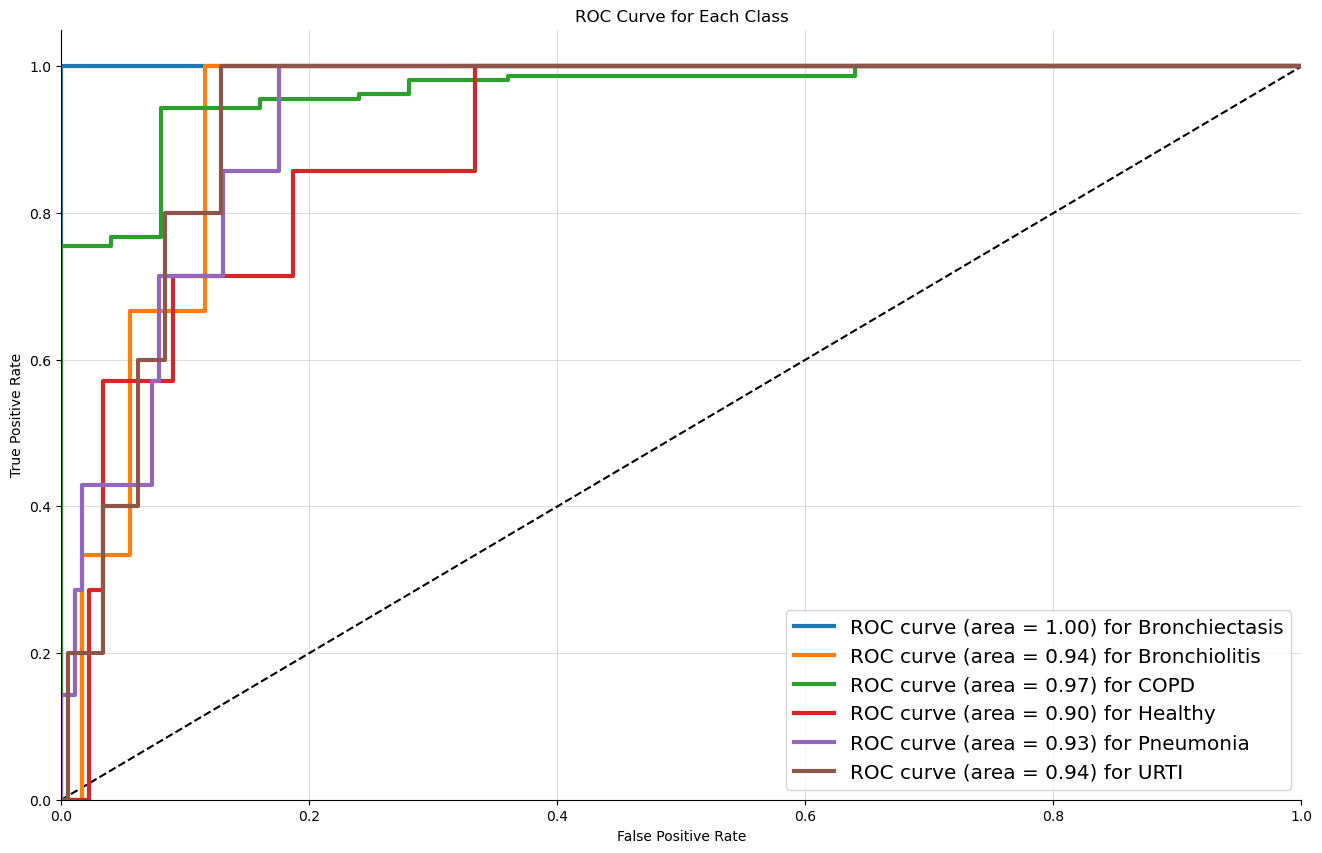

In [3]:
import numpy as np
from datetime import datetime
from os import listdir
from os.path import isfile, join
import librosa
import numpy as np
import pandas as pd
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Conv2D, MaxPooling2D, GlobalAveragePooling2D, Input
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import ModelCheckpoint
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc, accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier  # Import Random Forest
import matplotlib.pyplot as plt
import seaborn as sns

# File paths and loading data
mypath = "E:\\FFF\\respiratory-sound-database\\Respiratory_Sound_Database\\Respiratory_Sound_Database\\audio_and_txt_files\\"
filenames = [f for f in listdir(mypath) if (isfile(join(mypath, f)) and f.endswith('.wav'))]
p_id_in_file = [int(name[:3]) for name in filenames]
p_id_in_file = np.array(p_id_in_file)
max_pad_len = 862

# Feature extraction function
def extract_features(file_name):
    try:
        audio, sample_rate = librosa.load(file_name, res_type='kaiser_fast', duration=20)
        mfccs = librosa.feature.mfcc(y=audio, sr=sample_rate, n_mfcc=40)
        pad_width = max_pad_len - mfccs.shape[1]
        mfccs = np.pad(mfccs, pad_width=((0, 0), (0, pad_width)), mode='constant')
    except Exception as e:
        print(f"Error encountered while parsing file: {file_name}")
        print(f"Exception: {e}")
        return None 
    return mfccs

filepaths = [join(mypath, f) for f in filenames]
p_diag = pd.read_csv("E:\\FFF\\respiratory-sound-database\\Respiratory_Sound_Database\\Respiratory_Sound_Database\\patient_diagnosis.csv", header=None)
labels = np.array([p_diag[p_diag[0] == x][1].values[0] for x in p_id_in_file])
features = [extract_features(file_name) for file_name in filepaths]
features = np.array(features)

# Removing specific labels and converting labels
features1 = np.delete(features, np.where((labels == 'Asthma') | (labels == 'LRTI'))[0], axis=0)
labels1 = np.delete(labels, np.where((labels == 'Asthma') | (labels == 'LRTI'))[0], axis=0)

# One-hot encode labels
le = LabelEncoder()
i_labels = le.fit_transform(labels1)
oh_labels = to_categorical(i_labels)

# Reshape features for CNN
features1 = np.reshape(features1, (*features1.shape, 1))

# Train-test split
x_train, x_test, y_train, y_test = train_test_split(features1, oh_labels, stratify=oh_labels, test_size=0.2, random_state=42)

# Define CNN model for feature extraction
num_rows = 40
num_columns = 862
num_channels = 1
filter_size = 2

cnn_model = Sequential()
cnn_model.add(Input(shape=(num_rows, num_columns, num_channels)))
cnn_model.add(Conv2D(filters=16, kernel_size=filter_size, activation='relu'))
cnn_model.add(MaxPooling2D(pool_size=2))
cnn_model.add(Dropout(0.2))
cnn_model.add(Conv2D(filters=32, kernel_size=filter_size, activation='relu'))
cnn_model.add(MaxPooling2D(pool_size=2))
cnn_model.add(Dropout(0.2))
cnn_model.add(Conv2D(filters=64, kernel_size=filter_size, activation='relu'))
cnn_model.add(MaxPooling2D(pool_size=2))
cnn_model.add(Dropout(0.2))
cnn_model.add(Conv2D(filters=128, kernel_size=filter_size, activation='relu'))
cnn_model.add(MaxPooling2D(pool_size=2))
cnn_model.add(Dropout(0.2))
cnn_model.add(GlobalAveragePooling2D())

cnn_model.compile(loss='categorical_crossentropy', metrics=['accuracy'], optimizer='adam')
cnn_model.summary()

# Extract features using CNN
x_train_features = cnn_model.predict(x_train)
x_test_features = cnn_model.predict(x_test)

# Flatten the features for Random Forest
x_train_features = x_train_features.reshape(x_train_features.shape[0], -1)
x_test_features = x_test_features.reshape(x_test_features.shape[0], -1)

# Convert one-hot labels to single integers for Random Forest
y_train = np.argmax(y_train, axis=1)
y_test = np.argmax(y_test, axis=1)

# Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,  # Number of trees
    max_depth=6,       # Maximum tree depth
    random_state=42,   # Random seed
    class_weight='balanced'  # Handle class imbalance
)

# Train the Random Forest model
rf_model.fit(x_train_features, y_train)

# Evaluate model
y_pred = rf_model.predict(x_test_features)
accuracy = accuracy_score(y_test, y_pred)
print(f"Random Forest Test Accuracy: {accuracy:.4f}")

# Evaluating the model on the training set
y_train_pred = rf_model.predict(x_train_features)
train_accuracy = accuracy_score(y_train, y_train_pred)
print(f"Random Forest Training Accuracy: {train_accuracy:.4f}")

# Evaluating the model on the testing set
y_test_pred = rf_model.predict(x_test_features)
test_accuracy = accuracy_score(y_test, y_test_pred)
print(f"Random Forest Testing Accuracy: {test_accuracy:.4f}")

# Confusion matrix and classification report
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=le.classes_, zero_division=1))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Plot ROC curves
fpr = dict()
tpr = dict()
roc_auc = dict()
y_test_onehot = to_categorical(y_test, num_classes=len(le.classes_))
y_pred_proba = rf_model.predict_proba(x_test_features)
for i in range(len(le.classes_)):
    fpr[i], tpr[i], _ = roc_curve(y_test_onehot[:, i], y_pred_proba[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# ROC Curve Plot
fig, ax = plt.subplots(figsize=(16, 10))
ax.plot([0, 1], [0, 1], 'k--')
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve for Each Class')
for i in range(len(le.classes_)):
    ax.plot(fpr[i], tpr[i], linewidth=3, label='ROC curve (area = %0.2f) for %s' % (roc_auc[i], le.classes_[i]))
ax.legend(loc="best", fontsize='x-large')
ax.grid(alpha=.4)
sns.despine()
plt.show()